# Group Name: Team Vayu
# Group Leader Name: Shobana Balusamy
# Group Leader Registration Number: 23MID0212
# Students Name: Mohanraj I
# Students Registration Number: 23MID0121

# Titanic Survival Prediction

**Goal:** Train a first supervised machine-learning model to predict Titanic passenger survival.

This notebook:
1. Loads `train.csv` and `test.csv`
2. Inspects the data
3. Engineers a few simple features
4. Trains and validates a Logistic Regression model
5. Fits the pipeline on all labelled training data
6. Creates `submission.csv` for the Kaggle competition

## 1. Install / import libraries

In [3]:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the datasets

In [4]:
# Keep train.csv and test.csv in the same folder as this notebook.
# If they are in another folder, replace the paths below with the correct file paths.

train_path = "train.csv"
test_path = "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 3. Understand the data

In [5]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nMissing values in training data:")
display(train_df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nSurvival counts:")
display(train_df["Survived"].value_counts().rename(index={0: "Did not survive (0)", 1: "Survived (1)"}))

print("\nSurvival rate:")
print(f"{train_df['Survived'].mean():.1%}")

Training columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values in training data:


,missing_count
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0



Survival counts:


Survived
Did not survive (0)    549
Survived (1)           342
Name: count, dtype: int64


Survival rate:
38.4%


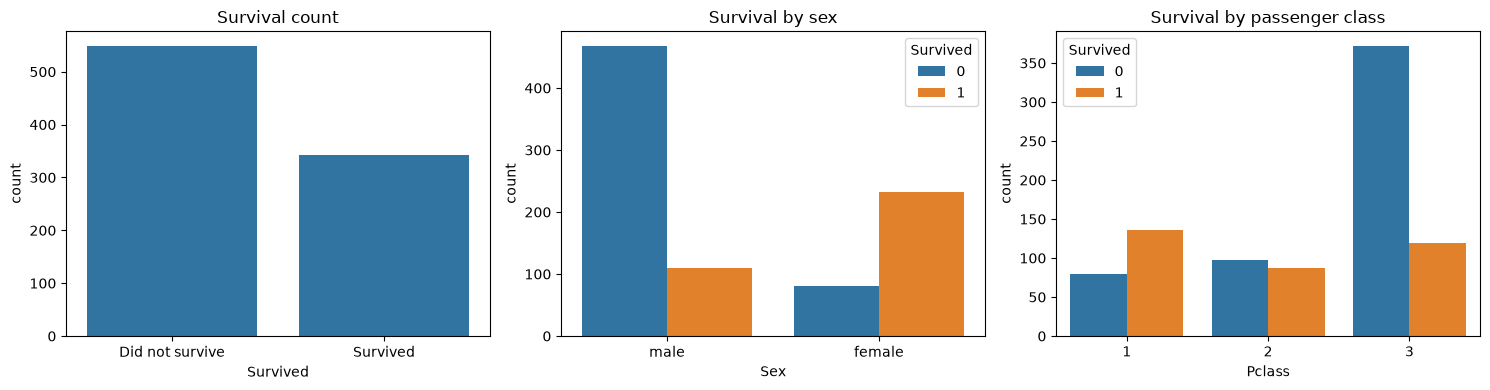

In [6]:
# Visualise the target distribution and a few relationships.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=train_df, x="Survived", ax=axes[0])
axes[0].set_title("Survival count")
axes[0].set_xticklabels(["Did not survive", "Survived"])

sns.countplot(data=train_df, x="Sex", hue="Survived", ax=axes[1])
axes[1].set_title("Survival by sex")

sns.countplot(data=train_df, x="Pclass", hue="Survived", ax=axes[2])
axes[2].set_title("Survival by passenger class")

plt.tight_layout()
plt.show()

## 4. Feature engineering

We will create:
- `FamilySize`: number of family members travelling with the passenger, including the passenger.
- `IsAlone`: whether the passenger travelled without listed parents/children or siblings/spouse.
- `Title`: a title extracted from the passenger's name (such as Mr, Mrs, Miss, or Master).

These are candidate features. We will evaluate their usefulness rather than assume they improve the model.

In [7]:
def add_features(df):
    df = df.copy()

    # Family size includes the passenger.
    df["FamilySize"] = df["SibSp"].fillna(0) + df["Parch"].fillna(0) + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # Extract a title from Name; use "Unknown" if extraction fails.
    if "Name" in df.columns:
        title = df["Name"].astype(str).str.extract(r",\s*([^.]*)\.", expand=False)
        title = title.fillna("Unknown").str.strip()

        # Combine rare titles into a smaller group.
        common_titles = {"Mr", "Mrs", "Miss", "Master"}
        df["Title"] = title.where(title.isin(common_titles), "Other")
    else:
        df["Title"] = "Unknown"

    return df

train_fe = add_features(train_df)
test_fe = add_features(test_df)

display(train_fe[["Name", "FamilySize", "IsAlone", "Title"]].head())

,Name,FamilySize,IsAlone,Title
0,"Braund, Mr. Owen Harris",2,0,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",2,0,Mrs
2,"Heikkinen, Miss. Laina",1,1,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",2,0,Mrs
4,"Allen, Mr. William Henry",1,1,Mr


## 5. Prepare features and target

In [8]:
TARGET = "Survived"

# PassengerId is kept for the final submission but not used as a predictive feature.
# Name, Ticket, and Cabin are omitted initially; Title is derived from Name.
feature_columns = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked",
    "FamilySize", "IsAlone", "Title"
]

X = train_fe[feature_columns].copy()
y = train_fe[TARGET].astype(int)
X_test = test_fe[feature_columns].copy()

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"
]
categorical_features = ["Sex", "Embarked", "Title"]

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Test feature matrix:", X_test.shape)

Feature matrix: (891, 10)
Target: (891,)
Test feature matrix: (418, 10)


## 6. Build the preprocessing and model pipeline

In [9]:
# Numerical fields: fill missing values with the median, then standardise.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical fields: fill missing values with the most frequent category,
# then one-hot encode categories that may not appear in every split.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

print("Pipeline created: preprocessing → Logistic Regression")

Pipeline created: preprocessing → Logistic Regression


## 7. Split data and train the initial model

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

model.fit(X_train, y_train)
valid_predictions = model.predict(X_valid)

accuracy = accuracy_score(y_valid, valid_predictions)
print(f"Validation accuracy: {accuracy:.4f} ({accuracy:.2%})")

print("\nClassification report:")
print(classification_report(
    y_valid,
    valid_predictions,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))

Validation accuracy: 0.8436 (84.36%)

Classification report:
                 precision    recall  f1-score   support

Did not survive       0.85      0.90      0.88       110
       Survived       0.83      0.75      0.79        69

       accuracy                           0.84       179
      macro avg       0.84      0.83      0.83       179
   weighted avg       0.84      0.84      0.84       179



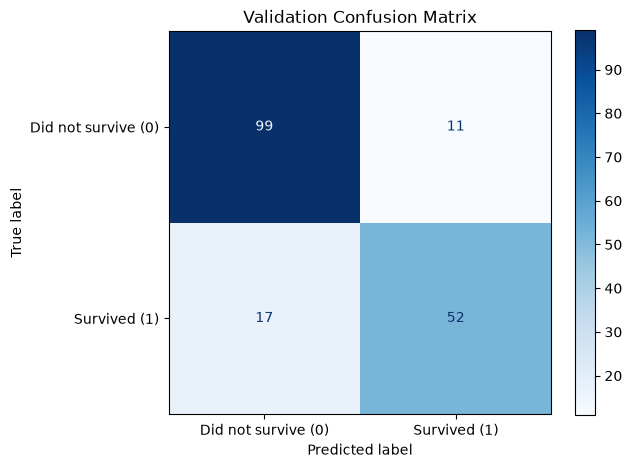

In [11]:
# Confusion matrix: shows correct and incorrect predictions for each class.
cm = confusion_matrix(y_valid, valid_predictions, labels=[0, 1])
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not survive (0)", "Survived (1)"]
)
display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Inspect model coefficients (optional)

In [12]:
# Logistic Regression coefficients offer a basic view of model direction.
# They are not proof of causation and should be interpreted carefully.
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

try:
    transformed_names = fitted_preprocessor.get_feature_names_out()
    coefficients = pd.DataFrame({
        "feature": transformed_names,
        "coefficient": fitted_classifier.coef_[0]
    })
    coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
    display(coefficients.sort_values("absolute_coefficient", ascending=False).head(15))
except Exception as error:
    print("Could not display feature names in this scikit-learn version:", error)

,feature,coefficient,absolute_coefficient
12,categorical__Title_Master,1.447664,1.447664
14,categorical__Title_Mr,-1.134892,1.134892
7,categorical__Sex_female,0.948485,0.948485
8,categorical__Sex_male,-0.858614,0.858614
0,numeric__Pclass,-0.838804,0.838804
16,categorical__Title_Other,-0.428846,0.428846
15,categorical__Title_Mrs,0.402545,0.402545
1,numeric__Age,-0.376962,0.376962
2,numeric__SibSp,-0.343652,0.343652
10,categorical__Embarked_Q,0.342852,0.342852


## 9. Train the final pipeline on all labelled data and predict the test set

After checking the validation results, this cell refits the same pipeline on all 891 labelled training records and predicts the 418 rows in `test.csv`.

**Important:** Kaggle's test labels are hidden, so the test-set accuracy cannot be calculated locally. The validation accuracy above is an estimate of generalisation performance.

In [13]:
# Refit on all labelled data.
model.fit(X, y)

test_predictions = model.predict(X_test).astype(int)

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions
})

submission.to_csv("submission.csv", index=False)

print("Submission file saved as submission.csv")
print("Submission shape:", submission.shape)
print("Predicted survival counts:")
display(submission["Survived"].value_counts().sort_index().rename(index={0: "Did not survive (0)", 1: "Survived (1)"}))
display(submission.head())

# Sanity checks for Kaggle submission format.
assert list(submission.columns) == ["PassengerId", "Survived"]
assert len(submission) == len(test_df)
assert submission["Survived"].isin([0, 1]).all()
print("Submission format checks passed.")

Submission file saved as submission.csv
Submission shape: (418, 2)
Predicted survival counts:


Survived
Did not survive (0)    253
Survived (1)           165
Name: count, dtype: int64

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


Submission format checks passed.


## 10. Save the trained model (optional)

In [14]:
# Optional: save the final fitted pipeline for later use.
# Install joblib if needed: %pip install joblib

import joblib
joblib.dump(model, "titanic_logistic_regression_pipeline.joblib")
print("Saved model: titanic_logistic_regression_pipeline.joblib")

Saved model: titanic_logistic_regression_pipeline.joblib
